# import library

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.dummy import DummyClassifier


import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier




from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score



# data processing

In [2]:
spambase = fetch_ucirepo(id=94)


In [3]:
X = spambase.data.features
y = spambase.data.targets.iloc[:, 0]  # Series nhãn (1 = spam, 0 = ham)

# 2. Kiểm tra điều kiện đầu vào trên X
assert X.shape == (4601, 57), f"Sai shape: nhận được {X.shape}, mong đợi (4601, 57)"
assert int(X.isna().sum().sum()) == 0, "Phát hiện giá trị thiếu trong X"
assert int((X < 0).sum().sum()) == 0, "Phát hiện giá trị âm trong X"
assert len(X) == len(y), "Số dòng giữa X và y không khớp"

# 3. Đếm số dòng trùng lặp hoàn toàn dựa trên 57 cột đặc trưng
dup_mask = X.duplicated(keep="first")  # True ở các dòng trùng lặp cần loại bỏ
dup_count = int(dup_mask.sum())
print(f"Số dòng trùng lặp hoàn toàn (dựa trên 57 đặc trưng): {dup_count}")

# 4. Loại bỏ dòng trùng trên X và loại bỏ đúng các dòng target tương ứng trên y
X_clean = X[~dup_mask].reset_index(drop=True)
y_clean = y[~dup_mask].reset_index(drop=True)

# 5. Kiểm tra lại sau khi loại trùng
assert X_clean.duplicated().sum() == 0, "Vẫn còn dòng trùng lặp trong X_clean!"
assert len(X_clean) == len(y_clean), "Sau khi lọc, số dòng của X_clean và y_clean không khớp!"

print(f"Sau khi lọc: X_clean = {X_clean.shape}, y_clean = {y_clean.shape}")
print("Phân bố nhãn sau khi lọc (0=ham, 1=spam):")
print(y_clean.value_counts(normalize=True).round(4))

Số dòng trùng lặp hoàn toàn (dựa trên 57 đặc trưng): 394
Sau khi lọc: X_clean = (4207, 57), y_clean = (4207,)
Phân bố nhãn sau khi lọc (0=ham, 1=spam):
Class
0    0.6009
1    0.3991
Name: proportion, dtype: float64


In [4]:
X_clean.head(3)

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259


# Splitting data for training, validation, and test.

In [5]:
class DatasetSplitter:
    """Thực hiện tách tập test ngay khi khởi tạo, giữ test khóa cho đến khi mở 1 lần."""

    def __init__(self, X, y, test_size=0.20, random_state=42):
        X_temp, X_test, y_temp, y_test = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=random_state,
            stratify=y,
        )
        self._X_temp = X_temp
        self._y_temp = y_temp
        self._X_test = X_test
        self._y_test = y_test
        self._test_opened = False

    def get_temp(self):
        """Lấy phần dữ liệu còn lại (80%) để chia tiếp train và validation."""
        return self._X_temp, self._y_temp

    def open_test(self):
        """Mở tập test đúng 1 lần duy nhất khi cần đánh giá cuối cùng."""
        if self._test_opened:
            raise RuntimeError(
                "Tập test đã được mở trước đó! Không được truy cập lại."
            )
        self._test_opened = True
        return self._X_test, self._y_test


# 1. Khởi tạo đối tượng và thực hiện chia lần 1 ngay bên trong class
splitter = DatasetSplitter(X_clean, y_clean, test_size=0.20, random_state=42)

# 2. Lấy phần còn lại (temp) ra để chia tiếp train (60%) và validation (20%)
X_temp, y_temp = splitter.get_temp()
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp,
)

# --- KIỂM TRA (ASSERT) ---

# Mở tập test thông qua đối tượng splitter (chỉ mở 1 lần để kiểm tra/tổng kết)
X_test, y_test = splitter.open_test()

# Xác nhận gọi open_test() lần thứ 2 sẽ báo lỗi
try:
    splitter.open_test()
    raise AssertionError("Lần gọi open_test() thứ 2 lẽ ra phải báo lỗi!")
except RuntimeError:
    pass

# 1. Tổng kích thước 3 tập phải khớp với X_clean / y_clean
total_len = len(X_clean)
assert len(X_train) + len(X_val) + len(X_test) == total_len, (
    "Tổng số mẫu 3 tập không khớp với dữ liệu gốc!"
)
assert (
    len(X_train) == len(y_train)
    and len(X_val) == len(y_val)
    and len(X_test) == len(y_test)
), "Số lượng X và y không khớp ở ít nhất một tập!"

# 2. Không có email nào xuất hiện trong hai tập (kiểm tra qua index gốc sau reset_index)
train_idx = set(X_train.index)
val_idx = set(X_val.index)
test_idx = set(X_test.index)

assert train_idx.isdisjoint(val_idx), "Trùng lặp mẫu giữa train và validation!"
assert train_idx.isdisjoint(test_idx), "Trùng lặp mẫu giữa train và test!"
assert val_idx.isdisjoint(test_idx), "Trùng lặp mẫu giữa validation và test!"

# 3. Mỗi tập giữ tỷ lệ spam xấp xỉ nhau (sai số tối đa 2% so với tỷ lệ gốc)
base_spam_rate = float(y_clean.mean())
for name, y_split in [("train", y_train), ("val", y_val), ("test", y_test)]:
    rate = float(y_split.mean())
    assert abs(rate - base_spam_rate) < 0.02, (
        f"Tỷ lệ spam ở tập {name} ({rate:.4f}) lệch quá nhiều so với gốc ({base_spam_rate:.4f})"
    )

# In thông tin tổng kết
for name, X_s, y_s in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    pct = len(X_s) / total_len * 100
    print(
        f"{name:10s}: shape={X_s.shape} ({pct:.1f}%) | tỷ lệ spam={y_s.mean():.4f}"
    )

Train     : shape=(2523, 57) (60.0%) | tỷ lệ spam=0.3991
Validation: shape=(842, 57) (20.0%) | tỷ lệ spam=0.3990
Test      : shape=(842, 57) (20.0%) | tỷ lệ spam=0.3990


# Check the same division method on the original file.

In [6]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp,
)

# 3. Đếm số email trong X_val có bản sao y hệt trong X_train (dựa trên 57 đặc trưng)
train_tuples = set(X_train.itertuples(index=False, name=None))
leak_count = sum(
    row in train_tuples
    for row in X_val.itertuples(index=False, name=None)
)

print(f"leak_count: {leak_count} / {len(X_val)} email trong validation có bản sao y hệt trong train")

leak_count: 83 / 920 email trong validation có bản sao y hệt trong train


# Exploratory Data Analysis

In [7]:


# 1. In mức cân bằng giữa các lớp trên tập train
class_counts = y_train.value_counts().sort_index()
class_ratios = y_train.value_counts(normalize=True).sort_index()

print("=== 1. MỨC CÂN BẰNG LỚP TRÊN TẬP TRAIN ===")
for label in class_counts.index:
    ten_lop = "Spam (1)" if label == 1 else "Ham (0)"
    print(
        f"{ten_lop:10s}: {int(class_counts[label]):4d} mẫu "
        f"({class_ratios[label] * 100:.2f}%)"
    )

# 2. Tính tương quan của 57 đặc trưng với nhãn spam trên tập train
# Xếp hạng theo độ lớn tuyệt đối |r|, nhưng giữ dấu gốc r để thấy chiều dương/âm
correlations = X_train.apply(lambda col: col.corr(y_train))

eda_corr_df = (
    pd.DataFrame({
        "feature": correlations.index,
        "corr_with_spam": correlations.values,
        "abs_corr": correlations.abs().values,
    })
    .sort_values(by="abs_corr", ascending=False)
    .reset_index(drop=True)
)

top10_corr = eda_corr_df.head(10)
print("\n=== 2. TOP 10 ĐẶC TRƯNG CÓ TƯƠNG QUAN MẠNH NHẤT VỚI SPAM (TRAIN) ===")
print(top10_corr[["feature", "corr_with_spam", "abs_corr"]].to_string(index=False))

# 3. Kiểm tra tính hợp lý so với trực giác bằng assert
corr_map = correlations.to_dict()

assert "word_freq_free" in corr_map, "Thiếu cột word_freq_free"
assert "char_freq_$" in corr_map, "Thiếu cột char_freq_$"
assert "word_freq_george" in corr_map, "Thiếu cột word_freq_george"

assert corr_map["word_freq_free"] > 0, (
    f"Kỳ vọng word_freq_free tương quan dương (> 0), nhưng nhận được {corr_map['word_freq_free']:.4f}"
)
assert corr_map["char_freq_$"] > 0, (
    f"Kỳ vọng char_freq_$ tương quan dương (> 0), nhưng nhận được {corr_map['char_freq_$']:.4f}"
)
assert corr_map["word_freq_george"] < 0, (
    f"Kỳ vọng word_freq_george tương quan âm (< 0), nhưng nhận được {corr_map['word_freq_george']:.4f}"
)

print("\n=== 3. KIỂM TRA TRỰC GIÁC THÀNH CÔNG ===")
print(f"word_freq_free   : r = {corr_map['word_freq_free']:+.4f} (> 0)")
print(f"char_freq_$      : r = {corr_map['char_freq_$']:+.4f} (> 0)")
print(f"word_freq_george : r = {corr_map['word_freq_george']:+.4f} (< 0)")

=== 1. MỨC CÂN BẰNG LỚP TRÊN TẬP TRAIN ===
Ham (0)   : 1672 mẫu (60.58%)
Spam (1)  : 1088 mẫu (39.42%)

=== 2. TOP 10 ĐẶC TRƯNG CÓ TƯƠNG QUAN MẠNH NHẤT VỚI SPAM (TRAIN) ===
                 feature  corr_with_spam  abs_corr
          word_freq_your        0.390909  0.390909
           word_freq_000        0.346055  0.346055
        word_freq_remove        0.321424  0.321424
             char_freq_$        0.314794  0.314794
capital_run_length_total        0.277991  0.277991
      word_freq_business        0.269835  0.269835
           word_freq_our        0.266320  0.266320
           word_freq_you        0.264509  0.264509
            word_freq_hp       -0.254871  0.254871
         word_freq_money        0.250302  0.250302

=== 3. KIỂM TRA TRỰC GIÁC THÀNH CÔNG ===
word_freq_free   : r = +0.2382 (> 0)
char_freq_$      : r = +0.3148 (> 0)
word_freq_george : r = -0.1849 (< 0)


# Check and select the standard floor level.

In [8]:


# 1. Khởi tạo và huấn luyện DummyClassifier trên tập train
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

# 2. Dự đoán và tính accuracy trên tập validation
val_pred_dummy = dummy_clf.predict(X_val)
baseline_val_acc = accuracy_score(y_val, val_pred_dummy)

# Tỷ lệ ham (nhãn 0) trong tập validation
expected_ham_rate = float((y_val == 0).mean())

# 3. Assert rằng accuracy của most_frequent bằng tỷ lệ ham trong tập validation
assert np.isclose(baseline_val_acc, expected_ham_rate, atol=1e-12), (
    f"Baseline accuracy ({baseline_val_acc:.6f}) không bằng tỷ lệ ham "
    f"ở tập validation ({expected_ham_rate:.6f})!"
)

print(f"Baseline (most_frequent) Validation Accuracy: {baseline_val_acc:.4f} ({baseline_val_acc * 100:.2f}%)")
print(f"Tỷ lệ ham trên tập validation               : {expected_ham_rate:.4f} ({expected_ham_rate * 100:.2f}%)")

Baseline (most_frequent) Validation Accuracy: 0.6065 (60.65%)
Tỷ lệ ham trên tập validation               : 0.6065 (60.65%)


# Choose the best model

=== BẢNG KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION ===
                        accuracy  precision  recall      f1  roc_auc
model                                                               
LogisticRegression        0.9293     0.9255  0.8923  0.9086   0.9772
GaussianNB                0.8196     0.7000  0.9475  0.8052   0.9472
DecisionTreeClassifier    0.9011     0.8652  0.8867  0.8759   0.8986

Mô hình thắng cuộc theo quy tắc pick_best(): LogisticRegression


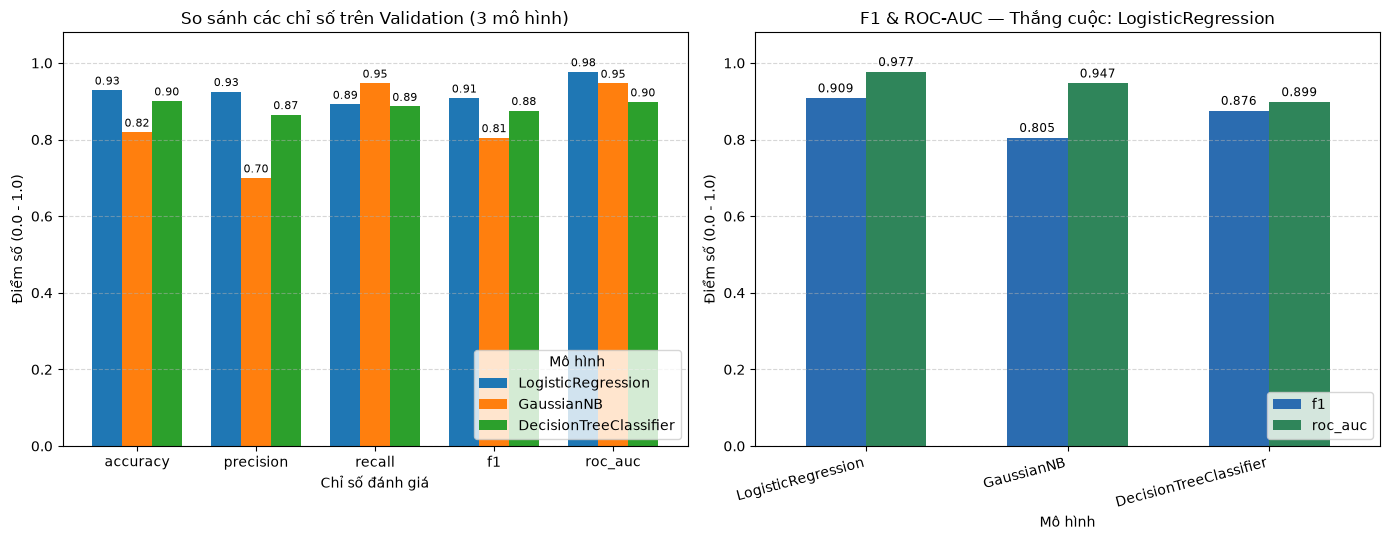

In [9]:


# 1. Định nghĩa các bộ phân loại (bọc StandardScaler trong Pipeline cho LogisticRegression)
models = {
    "LogisticRegression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42),
    ),
    "GaussianNB": GaussianNB(),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),
}

# 2. Huấn luyện trên tập train và đánh giá trên tập validation
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)

    y_val_pred = model.predict(X_val)
    # Lấy xác suất lớp dương (1 = spam) cho ROC-AUC
    y_val_proba = model.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_val_pred)
    prec = precision_score(y_val, y_val_pred, zero_division=0)
    rec = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)
    roc_auc = roc_auc_score(y_val, y_val_proba)

    # Kiểm tra phải vượt qua mức sàn baseline (nếu đã có biến baseline_val_acc)
    if "baseline_val_acc" in globals():

        assert acc > baseline_val_acc, (
            f"{name} chưa vượt baseline: acc={acc:.4f} <= {baseline_val_acc:.4f}"
        )

    rows.append({
        "model": name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "roc_auc": roc_auc,
    })

results_df = pd.DataFrame(rows).set_index("model")
print("=== BẢNG KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION ===")
print(results_df.round(4).to_string())


# 3. Hàm chọn mô hình thắng cuộc theo quy tắc có thể lặp lại
def pick_best(table: pd.DataFrame, primary: str = "f1", secondary: str = "roc_auc") -> str:
    """
    Chọn mô hình tốt nhất dựa trên cột điểm chính (mặc định: 'f1'),
    phá thế hòa bằng cột điểm phụ (mặc định: 'roc_auc').
    """
    required_cols = [primary, secondary]
    for col in required_cols:
        if col not in table.columns:
            raise ValueError(f"Thiếu cột '{col}' trong bảng kết quả.")

    ranked = table.sort_values(by=[primary, secondary], ascending=[False, False])
    return str(ranked.index[0])


best_model_name = pick_best(results_df)
print(f"\nMô hình thắng cuộc theo quy tắc pick_best(): {best_model_name}")

# 4. Vẽ biểu đồ trực quan kết quả của 3 mô hình trên tập validation
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
plot_df = results_df[metrics]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Biểu đồ 1: So sánh tất cả các chỉ số theo từng mô hình (Grouped Bar Chart)
ax1 = axes[0]
plot_df.T.plot(kind="bar", ax=ax1, width=0.75)
ax1.set_title("So sánh các chỉ số trên Validation (3 mô hình)")
ax1.set_xlabel("Chỉ số đánh giá")
ax1.set_ylabel("Điểm số (0.0 - 1.0)")
ax1.set_ylim(0, 1.08)
ax1.set_xticklabels(metrics, rotation=0)
ax1.legend(title="Mô hình", loc="lower right")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for container in ax1.containers:
    ax1.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

# Biểu đồ 2: Tập trung so sánh F1 và ROC-AUC (thước đo cốt lõi cho lọc spam)
ax2 = axes[1]
core_df = plot_df[["f1", "roc_auc"]]
core_df.plot(kind="bar", ax=ax2, width=0.6, color=["#2b6cb0", "#2f855a"])
ax2.set_title(f"F1 & ROC-AUC — Thắng cuộc: {best_model_name}")
ax2.set_xlabel("Mô hình")
ax2.set_ylabel("Điểm số (0.0 - 1.0)")
ax2.set_ylim(0, 1.08)
ax2.set_xticklabels(core_df.index, rotation=15, ha="right")
ax2.legend(loc="lower right")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.3f", fontsize=8.5, padding=2)

plt.tight_layout()
plt.show()

# Choose the best hyperparameter set.

/home/hoan.nguyen@rikai.technology/hoan_intern_rikai/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/hoan.nguyen@rikai.technology/hoan_intern_rikai/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of p

Mô hình tinh chỉnh : LogisticRegression
Siêu tham số tốt nhất: {'logisticregression__C': 1.0, 'logisticregression__penalty': 'l2', 'logisticregression__solver': 'lbfgs'}
5-fold CV F1 (untuned): [0.9091, 0.8647, 0.8818, 0.8991, 0.9224]
fold_std              : 0.0227
untuned_f1 (val)      : 0.9086
tuned_f1 (val)        : 0.9086
gain                  : +0.0000
tuning_worth_it       : False (gain > fold_std: 0.0000 > 0.0227)

=== SO SÁNH TRÊN TẬP VALIDATION ===
         accuracy  precision  recall      f1  roc_auc
Untuned    0.9293     0.9255  0.8923  0.9086   0.9772
Tuned      0.9293     0.9255  0.8923  0.9086   0.9772


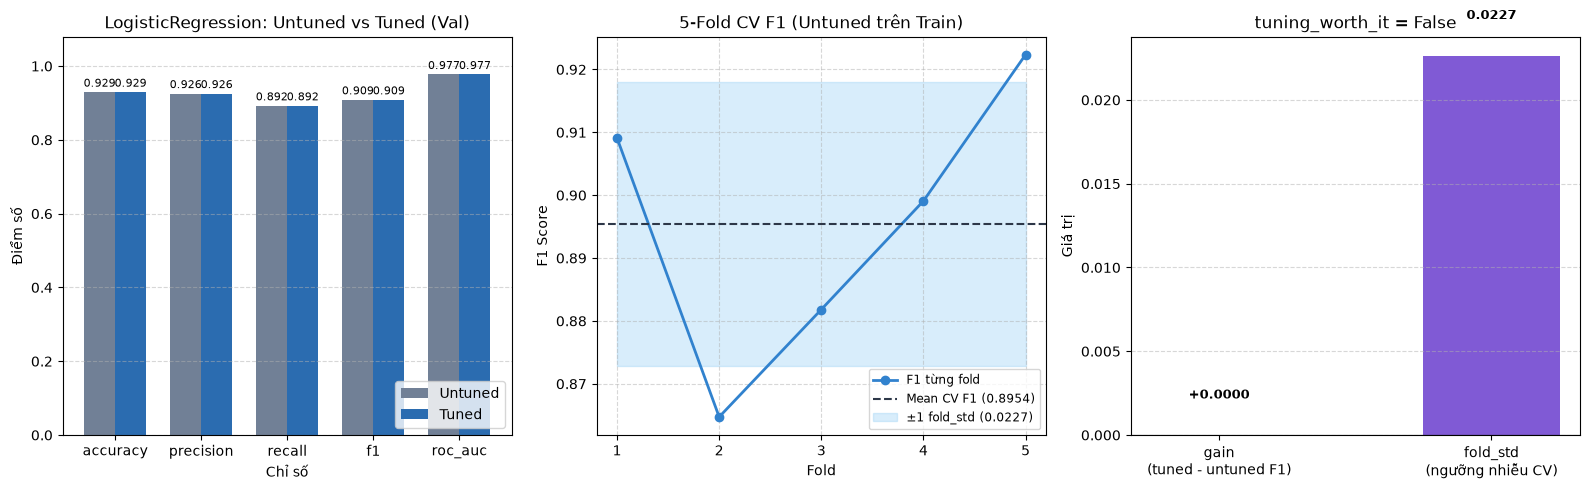

In [10]:


# 1. Xác định mô hình chưa tinh chỉnh & lưới siêu tham số (>= 2 tham số) theo best_model_name
target_model = best_model_name if "best_model_name" in globals() else "LogisticRegression"

if target_model == "LogisticRegression":
    untuned_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42),
    )
    param_grid = {
        "logisticregression__C": [0.01, 0.1, 1.0, 10.0],
        "logisticregression__penalty": ["l2"],
        "logisticregression__solver": ["lbfgs", "liblinear"],
    }
elif target_model == "DecisionTreeClassifier":
    untuned_model = DecisionTreeClassifier(random_state=42)
    param_grid = {
        "max_depth": [3, 5, 10, 15, None],
        "min_samples_split": [2, 5, 10, 20],
        "min_samples_leaf": [1, 2, 5],
    }
elif target_model == "GaussianNB":
    untuned_model = GaussianNB()
    param_grid = {
        "var_smoothing": np.logspace(-12, -6, 7),
    }
else:
    raise ValueError(f"Chưa cấu hình lưới tham số cho mô hình: {target_model}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Đo độ lệch chuẩn F1 giữa các fold trong 5-fold CV của mô hình chưa tinh chỉnh (chỉ trên train)
cv_f1_scores = cross_val_score(
    untuned_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
)
fold_std = float(np.std(cv_f1_scores, ddof=1))

# Huấn luyện mô hình chưa tinh chỉnh trên toàn bộ tập train và đánh giá trên validation
untuned_model.fit(X_train, y_train)
val_pred_untuned = untuned_model.predict(X_val)
val_proba_untuned = untuned_model.predict_proba(X_val)[:, 1]

untuned_metrics = {
    "accuracy": accuracy_score(y_val, val_pred_untuned),
    "precision": precision_score(y_val, val_pred_untuned, zero_division=0),
    "recall": recall_score(y_val, val_pred_untuned, zero_division=0),
    "f1": f1_score(y_val, val_pred_untuned, zero_division=0),
    "roc_auc": roc_auc_score(y_val, val_proba_untuned),
}

# 3. Tinh chỉnh bằng GridSearchCV (CV chỉ trên tập train)
grid_search = GridSearchCV(
    estimator=untuned_model,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    refit=True,
)
grid_search.fit(X_train, y_train)

best_tuned_model = grid_search.best_estimator_
val_pred_tuned = best_tuned_model.predict(X_val)
val_proba_tuned = best_tuned_model.predict_proba(X_val)[:, 1]

tuned_metrics = {
    "accuracy": accuracy_score(y_val, val_pred_tuned),
    "precision": precision_score(y_val, val_pred_tuned, zero_division=0),
    "recall": recall_score(y_val, val_pred_tuned, zero_division=0),
    "f1": f1_score(y_val, val_pred_tuned, zero_division=0),
    "roc_auc": roc_auc_score(y_val, val_proba_tuned),
}

# 4. Tính gain, fold_std và tuning_worth_it
untuned_f1 = float(untuned_metrics["f1"])
tuned_f1 = float(tuned_metrics["f1"])
gain = tuned_f1 - untuned_f1
tuning_worth_it = bool(gain > fold_std)

compare_df = pd.DataFrame(
    [untuned_metrics, tuned_metrics],
    index=["Untuned", "Tuned"],
)

print(f"Mô hình tinh chỉnh : {target_model}")
print(f"Siêu tham số tốt nhất: {grid_search.best_params_}")
print(f"5-fold CV F1 (untuned): {[round(float(s), 4) for s in cv_f1_scores]}")
print(f"fold_std              : {fold_std:.4f}")
print(f"untuned_f1 (val)      : {untuned_f1:.4f}")
print(f"tuned_f1 (val)        : {tuned_f1:.4f}")
print(f"gain                  : {gain:+.4f}")
print(f"tuning_worth_it       : {tuning_worth_it} (gain > fold_std: {gain:.4f} > {fold_std:.4f})\n")
print("=== SO SÁNH TRÊN TẬP VALIDATION ===")
print(compare_df.round(4).to_string())

# 5. Trực quan hóa bằng matplotlib
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Khung 1: So sánh các chỉ số trên Validation (Untuned vs Tuned)
ax1 = axes[0]
compare_df.T.plot(kind="bar", ax=ax1, width=0.72, color=["#718096", "#2b6cb0"])
ax1.set_title(f"{target_model}: Untuned vs Tuned (Val)")
ax1.set_xlabel("Chỉ số")
ax1.set_ylabel("Điểm số")
ax1.set_ylim(0, 1.08)
ax1.set_xticklabels(compare_df.columns, rotation=0)
ax1.legend(loc="lower right")
ax1.grid(axis="y", linestyle="--", alpha=0.5)
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.3f", fontsize=8, padding=2)

# Khung 2: F1 qua từng fold của mô hình chưa tinh chỉnh & vùng +- fold_std
ax2 = axes[1]
folds = np.arange(1, len(cv_f1_scores) + 1)
mean_cv_f1 = float(np.mean(cv_f1_scores))
ax2.plot(folds, cv_f1_scores, marker="o", linewidth=2, color="#3182ce", label="F1 từng fold")
ax2.axhline(mean_cv_f1, color="#2d3748", linestyle="--", label=f"Mean CV F1 ({mean_cv_f1:.4f})")
ax2.fill_between(
    folds,
    mean_cv_f1 - fold_std,
    mean_cv_f1 + fold_std,
    color="#90cdf4",
    alpha=0.35,
    label=f"±1 fold_std ({fold_std:.4f})",
)
ax2.set_title("5-Fold CV F1 (Untuned trên Train)")
ax2.set_xlabel("Fold")
ax2.set_ylabel("F1 Score")
ax2.set_xticks(folds)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower right", fontsize=8.5)

# Khung 3: So sánh gain thực tế với ngưỡng fold_std
ax3 = axes[2]
bars = ax3.bar(
    ["gain\n(tuned - untuned F1)", "fold_std\n(ngưỡng nhiễu CV)"],
    [gain, fold_std],
    width=0.5,
    color=["#2f855a" if tuning_worth_it else "#dd6b20", "#805ad5"],
)
ax3.axhline(0, color="black", linewidth=0.8)
ax3.set_title(f"tuning_worth_it = {tuning_worth_it}")
ax3.set_ylabel("Giá trị")
ax3.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars:
    h = bar.get_height()
    va = "bottom" if h >= 0 else "top"
    offset = 0.002 if h >= 0 else -0.002
    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        h + offset,
        f"{h:+.4f}" if bar is bars[0] else f"{h:.4f}",
        ha="center",
        va=va,
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()
plt.show()